# Did DAZN's Open Days move interest in Spain? A CausalImpact analysis with public data

From 1 to 5 October 2026, DAZN opened part of its catalogue in Spain for free (UEFA Nations League, LaLiga Hypermotion, acb basketball and more) to anyone who signed up with an email. The promotion ran only in Spain.

The question I want to answer: **did the Open Days increase interest in DAZN, or would that bump have happened anyway?**

The cleanest way to measure this would be an A/B test, with both versions running in parallel. That is not possible here: the promotion went live for everyone in Spain at once, and I only have public data. So I use **CausalImpact**, which estimates what would have happened without the promotion (the counterfactual) from control series that were not affected by it, and compares that with what actually happened.

**Data.** Daily Google Trends interest from 1 August to 15 October 2026. Google Trends is a 0-100 index relative to the busiest day of each series, not a count of searches or sign-ups, so this measures public interest, not subscriptions.

| Series | Role |
|---|---|
| "DAZN" searches in Spain | Treated series |
| "LaLiga" searches in Spain | Main control |
| "DAZN" searches in Germany and Italy | Extra controls (robustness check) |
| "DAZN" searches in Portugal | Loaded but not used (too many zero days) |

## 1. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Loading the data

Each CSV comes straight from Google Trends. I parse the dates and use them as the index, which makes it easy to slice by period and to line the series up day by day.

In [2]:
# Parse the dates and use them as the index, so the series can be sliced by period
dazn_es = pd.read_csv('Data/dazn_es.csv', parse_dates=['Time'], index_col=['Time'])
dazn_de = pd.read_csv('Data/dazn_de.csv', parse_dates=['Time'], index_col=['Time'])
dazn_it = pd.read_csv('Data/dazn_it.csv', parse_dates=['Time'], index_col=['Time'])
dazn_pt = pd.read_csv('Data/dazn_pt.csv', parse_dates=['Time'], index_col=['Time'])
laliga_es = pd.read_csv('Data/laliga_es.csv', parse_dates=['Time'], index_col=['Time'])
display(dazn_es.head())
display(laliga_es.head())
display(dazn_de.head())


,DAZN
Time,
2026-08-01,14
2026-08-02,12
2026-08-03,10
2026-08-04,9
2026-08-05,11


,Laliga
Time,
2026-08-01,5
2026-08-02,4
2026-08-03,4
2026-08-04,5
2026-08-05,5


,DAZN
Time,
2026-08-01,27
2026-08-02,15
2026-08-03,11
2026-08-04,11
2026-08-05,15


All five series go into one table, one column per series. The original column names repeat ("DAZN" appears four times), so I rename them.

In [3]:
# Put the five series side by side, aligned by date
df = pd.concat([dazn_es, laliga_es, dazn_de, dazn_it, dazn_pt], axis=1)

# Rename the columns, since four of them are called 'DAZN'
df.columns = ['dazn_es', 'laliga_es', 'dazn_de', 'dazn_it', 'dazn_pt']
df.head()

,dazn_es,laliga_es,dazn_de,dazn_it,dazn_pt
Time,,,,,
2026-08-01,14,5,27,20,31
2026-08-02,12,4,15,14,20
2026-08-03,10,4,11,12,14
2026-08-04,9,5,11,15,23
2026-08-05,11,5,15,24,23


## 3. Exploring the series

Before modelling, I check whether the control moves with the treated series. "LaLiga" works as a control because it follows the Spanish football calendar (weekends, big matches, the international break), but the Open Days did not include LaLiga EA Sports matches, so the promotion should not move it.

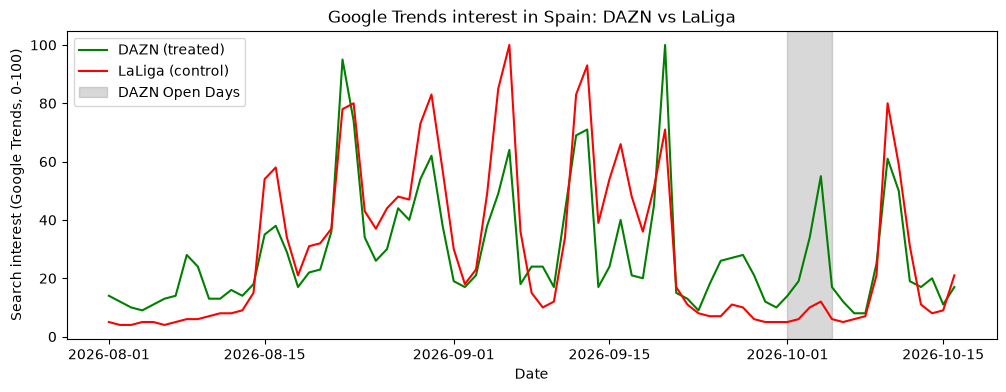

In [4]:
plt.figure(figsize = (12 , 4))
plt.plot('dazn_es', color='green', data=df)
plt.plot('laliga_es', color='r', data=df)
plt.title('Google Trends interest in Spain: DAZN vs LaLiga')
plt.xlabel('Date')
plt.ylabel('Search interest (Google Trends, 0-100)')
plt.axvspan(xmin='2026-10-01', xmax='2026-10-05', color='grey', alpha=0.3)
plt.legend(labels=['DAZN (treated)', 'LaLiga (control)', 'DAZN Open Days'])

**What the chart shows**

- From mid-August, both series rise and fall together on matchdays (correlation of about 0.85 before October).
- Before 15 August "LaLiga" is almost flat because the season had not started yet. DAZN still moves, driven by other sports.
- From 21 September to 8 October there is an international break and LaLiga searches drop close to zero. The Open Days fall inside this break, and DAZN shows a clear peak on 3 and 4 October while LaLiga barely moves.

## 4. Main analysis

- **Pre-period (1 Aug to 30 Sep):** the model learns how "DAZN" relates to "LaLiga".
- **Post-period (1 to 5 Oct):** the Open Days.

I keep the pre-season days (1 to 14 August) because, like the Open Days, they are days without LaLiga matches, so the model gets to see how DAZN behaves when there is no league. Section 5 checks what happens without them.

In [5]:
# Pre-period: the model learns how 'DAZN' relates to 'LaLiga'
pre_period = ['2026-08-01', '2026-09-30']

# Post-period: the Open Days
post_period = ['2026-10-01', '2026-10-05']

# The first column is the treated series and the rest are controls
# The table ends on the last day of the Open Days
data = df[['dazn_es', 'laliga_es']].loc['2026-08-01': '2026-10-05']

# CausalImpact works with decimal numbers
data = data.astype(float)
data

,dazn_es,laliga_es
Time,,
2026-08-01,14.0,5.0
2026-08-02,12.0,4.0
2026-08-03,10.0,4.0
2026-08-04,9.0,5.0
2026-08-05,11.0,5.0
...,...,...
2026-10-01,14.0,5.0
2026-10-02,19.0,6.0
2026-10-03,34.0,10.0


CausalImpact treats the first column as the treated series and every other column as a control. The model has a random component, so I fix a seed to make the results reproducible.

In [6]:
from causalimpact import CausalImpact
import tensorflow as tf

# Hide TensorFlow warnings so the output stays clean
tf.get_logger().setLevel('ERROR') 

# Fix the seed so the results are the same every time the notebook runs
tf.random.set_seed(24)

ci = CausalImpact(data, pre_period, post_period)

In [7]:
print(ci.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    27.8               139.0
Prediction (s.d.)         16.79 (5.85)       83.97 (29.26)
95% CI                    [5.48, 28.42]      [27.38, 142.08]

Absolute effect (s.d.)    11.01 (5.85)       55.03 (29.26)
95% CI                    [-0.62, 22.32]     [-3.08, 111.62]

Relative effect (s.d.)    65.53% (34.84%)    65.53% (34.84%)
95% CI                    [-3.66%, 132.92%]  [-3.66%, 132.92%]

Posterior tail-area probability p: 0.03
Posterior prob. of a causal effect: 96.7%

For more details run the command: print(impact.summary('report'))


**Reading the summary**

- During the Open Days, interest in DAZN was clearly above what the model expected without the promotion: the estimated relative effect is **+65.5%**.
- The posterior probability of a causal effect is **96.7%** (p = 0.033), so by the library's test the effect is statistically significant. The summary rounds p to two decimals (0.03); throughout this notebook I use the exact values, which are collected in the results table in section 8.
- The 95% interval goes from **-3.7% to +132.9%**: it is very wide and just crosses zero, so the size of the effect is very uncertain. The p-value comes from a one-sided test and the interval is two-sided, which is why both can be true at the same time.

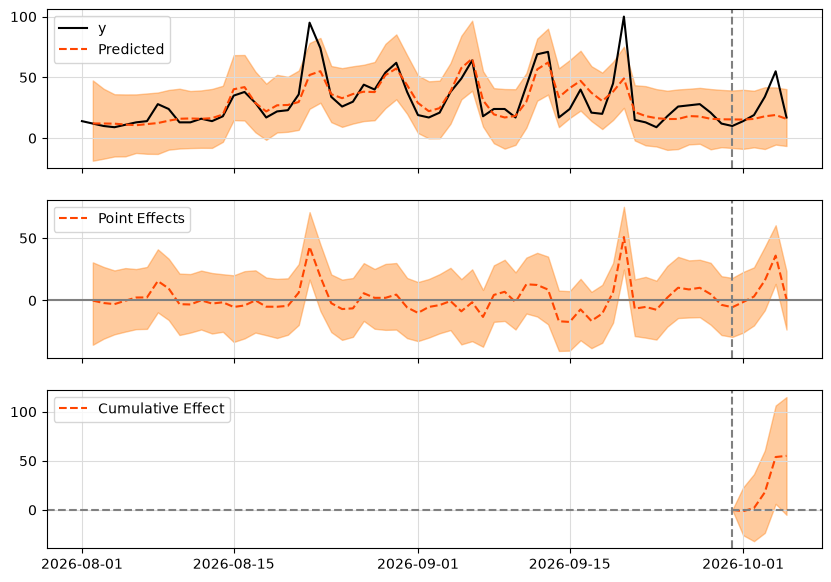

In [8]:
ci.plot()

**Reading the chart**

The three panels show: at the top, the real series (black) against the model's prediction of what would have happened without the Open Days (orange dashed line, with its 95% band); in the middle, the daily effect, which is the gap between the two; at the bottom, that effect added up over the post-period.

- In the pre-period the prediction follows the real series closely, which is what makes the counterfactual credible. It does miss two big peaks (22 August and 20 September), so the model is not perfect.
- During the Open Days the gap opens up and peaks on 4 October, the only day when the whole orange band (the 95% interval) stays above zero. On 5 October, the last day of the analysis, the cumulative effect is still positive, but the lower edge of its band sits just below zero, in line with the interval in the summary.

## 5. Robustness check 1: training from 15 August

Here I drop the pre-season and train the model only from the start of the LaLiga season.

In [9]:
# Same analysis, but training from the start of the LaLiga season
pre_period_aug15 = ['2026-08-15', '2026-09-30']
data_aug15 = df[['dazn_es', 'laliga_es']].loc['2026-08-15':'2026-10-05']
data_aug15 = data_aug15.astype(float)
data_aug15.tail()

,dazn_es,laliga_es
Time,,
2026-10-01,14.0,5.0
2026-10-02,19.0,6.0
2026-10-03,34.0,10.0
2026-10-04,55.0,12.0
2026-10-05,17.0,6.0


In [10]:
# Same seed as the main model, so the results can be compared
tf.random.set_seed(24)
ci_aug15 = CausalImpact(data_aug15, pre_period_aug15, post_period)

In [11]:
print(ci_aug15.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    27.8               139.0
Prediction (s.d.)         16.47 (7.41)       82.37 (37.04)
95% CI                    [1.67, 30.71]      [8.36, 153.56]

Absolute effect (s.d.)    11.33 (7.41)       56.63 (37.04)
95% CI                    [-2.91, 26.13]     [-14.56, 130.64]

Relative effect (s.d.)    68.75% (44.97%)    68.75% (44.97%)
95% CI                    [-17.67%, 158.61%] [-17.67%, 158.61%]

Posterior tail-area probability p: 0.06
Posterior prob. of a causal effect: 94.21%

For more details run the command: print(impact.summary('report'))


With a shorter training period the estimated effect is similar (**+68.8%**) but less certain: **p = 0.058**, so it is no longer significant at the usual 0.05 threshold. With fewer no-league days to learn from, the interval gets wider and reaches further below zero (-17.7%, against -3.7% in the main model).

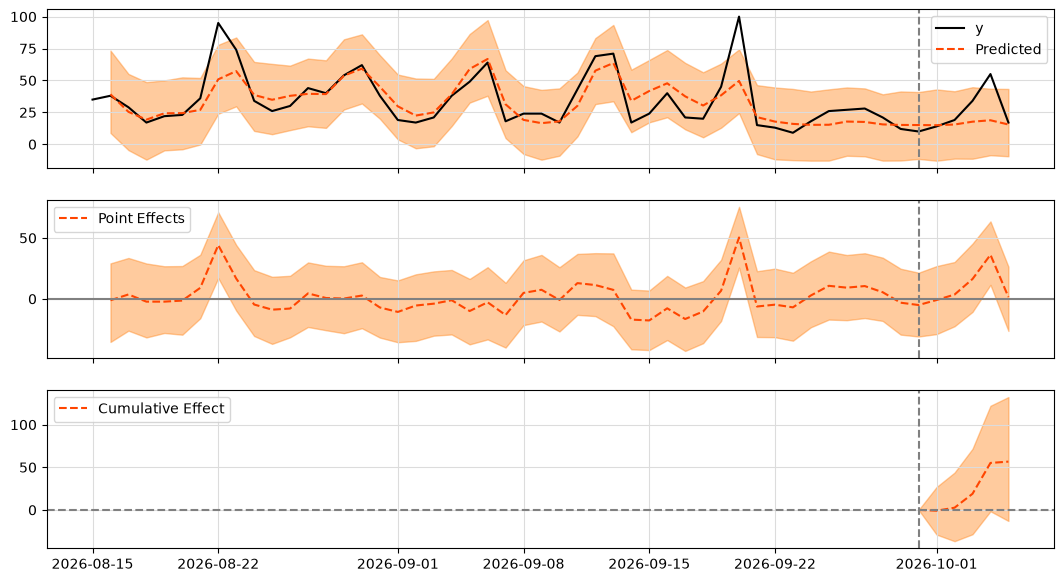

In [12]:
ci_aug15.plot(figsize=(13,7))

The chart tells the same story: the pre-period fit looks like the main model, but the bands are wider, and on 5 October, the last day, the lower edge of the cumulative band sits clearly below zero.

## 6. Placebo test

A placebo test checks whether the model invents effects. I pretend the Open Days happened on 24 to 28 September, a week with no promotion. That week is also part of the international break, just like the real Open Days, so it tests the model under the same conditions.

In [13]:
# Fake intervention: a week with no promotion, also during the international break
pre_period_placebo = ['2026-08-01', '2026-09-23']
post_period_placebo = ['2026-09-24', '2026-09-28']

# The table ends on 28 Sep so the real Open Days do not leak into the test
data_placebo = df[['dazn_es', 'laliga_es']].loc['2026-08-01':'2026-09-28']
data_placebo = data_placebo.astype(float)
data_placebo.tail()

,dazn_es,laliga_es
Time,,
2026-09-24,18.0,7.0
2026-09-25,26.0,7.0
2026-09-26,27.0,11.0
2026-09-27,28.0,10.0
2026-09-28,21.0,6.0


In [14]:
# Same seed as the main model, so the results can be compared
tf.random.set_seed(24)
ci_placebo = CausalImpact(data_placebo, pre_period_placebo, post_period_placebo)

In [15]:
print(ci_placebo.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    24.0               120.0
Prediction (s.d.)         15.64 (6.65)       78.18 (33.23)
95% CI                    [2.53, 28.58]      [12.64, 142.89]

Absolute effect (s.d.)    8.36 (6.65)        41.82 (33.23)
95% CI                    [-4.58, 21.47]     [-22.89, 107.36]

Relative effect (s.d.)    53.5% (42.5%)      53.5% (42.5%)
95% CI                    [-29.28%, 137.33%] [-29.28%, 137.33%]

Posterior tail-area probability p: 0.1
Posterior prob. of a causal effect: 90.41%

For more details run the command: print(impact.summary('report'))


The model does not call it significant (**p = 0.096**), which is what we want. But the fake effect is large: **+53.5%**. During the break LaLiga searches collapse while DAZN searches do not fall as much (people keep looking for it for other sports, such as the Nations League), and the model reads that gap as an effect. This suggests that part of the main +65.5% is this break effect and not the promotion.

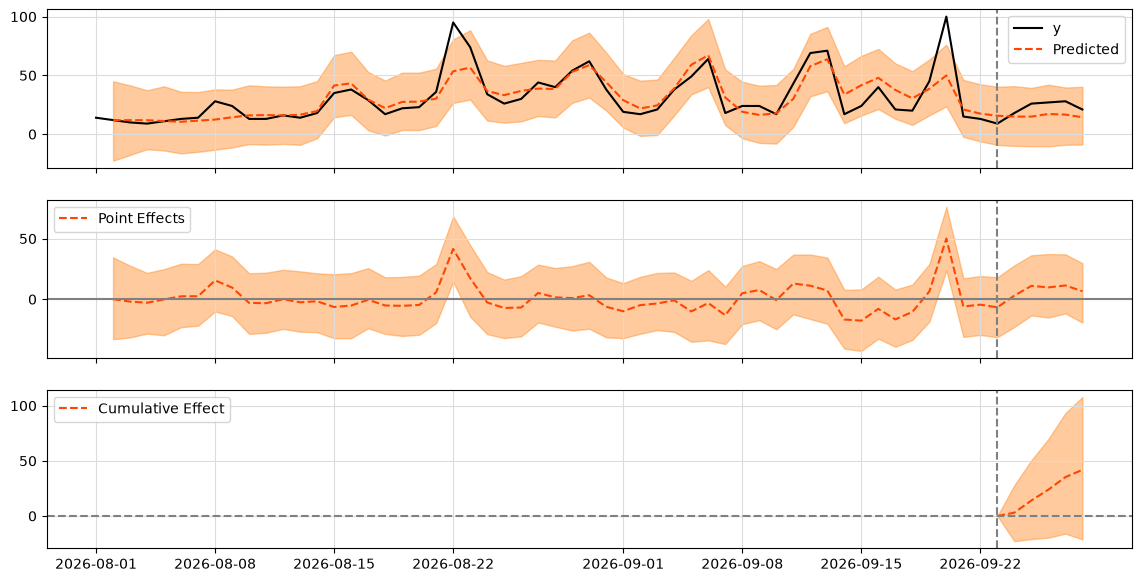

In [16]:
ci_placebo.plot(figsize=(14,7))

In the fake week the daily effect (the gap between the real and the predicted line) stays small, around +10, and its orange band includes zero on every day. The lower edge of the cumulative band also stays below zero. Day by day the model sees nothing clear, but because the expected values that week are low (about 15), these small gaps add up to a large relative effect.

## 7. Robustness check 2: adding Germany and Italy

"LaLiga" is a single control. Here I add DAZN searches in Germany and Italy, which can capture general interest in DAZN and the international break, since it happened across Europe at the same time. Portugal stays out because Google Trends returns zero on several days, which means there was too little search volume to measure.

In [17]:
# Add Germany and Italy as extra controls (Portugal is left out: too many zero days)
data_multi = df[['dazn_es', 'laliga_es', 'dazn_de', 'dazn_it']].loc['2026-08-01':'2026-10-05']
data_multi = data_multi.astype(float)
data_multi.tail()

,dazn_es,laliga_es,dazn_de,dazn_it
Time,,,,
2026-10-01,14.0,5.0,11.0,6.0
2026-10-02,19.0,6.0,19.0,5.0
2026-10-03,34.0,10.0,20.0,6.0
2026-10-04,55.0,12.0,29.0,9.0
2026-10-05,17.0,6.0,14.0,6.0


In [18]:
# Same seed as the main model, so the results can be compared
tf.random.set_seed(24)
ci_multi = CausalImpact(data_multi, pre_period, post_period)

In [19]:
print(ci_multi.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    27.8               139.0
Prediction (s.d.)         12.9 (6.0)         64.48 (30.02)
95% CI                    [0.82, 24.35]      [4.11, 121.77]

Absolute effect (s.d.)    14.9 (6.0)         74.52 (30.02)
95% CI                    [3.45, 26.98]      [17.23, 134.89]

Relative effect (s.d.)    115.56% (46.55%)   115.56% (46.55%)
95% CI                    [26.72%, 209.18%]  [26.72%, 209.18%]

Posterior tail-area probability p: 0.01
Posterior prob. of a causal effect: 99.4%

For more details run the command: print(impact.summary('report'))


The effect gets bigger (**+115.6%**, p = 0.006). A higher probability does not mean a better model here: Italian searches drop very low during the break, so the model expects even less DAZN interest in Spain and the gap grows. I read this as an upper bound, probably inflated, rather than as a more accurate estimate.

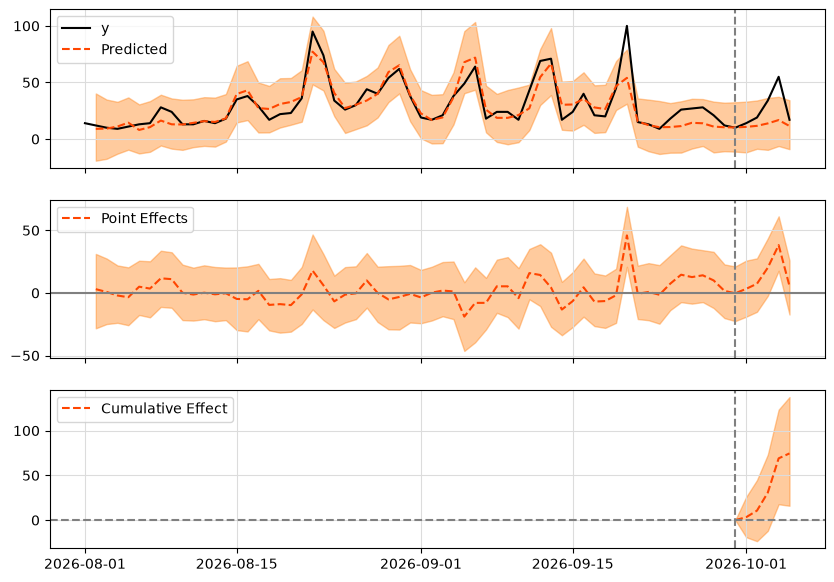

In [20]:
ci_multi.plot()

With Germany and Italy the model also gets closer to the 22 August peak (Italian searches peaked that day too). During the Open Days the predicted line sits lower than in the main model (12.9 on average against 16.8), and on 5 October, the last day, the whole cumulative band stays above zero, which matches the significant result.

## 8. Summary of results

In [21]:
# Collect the key numbers of every model in one table
models = {
    'Main (LaLiga, from Aug 1)':ci,
    'Robustness: from Aug 15':ci_aug15,
    'Robustness: + Germany and Italy':ci_multi,
    'Placebo (Sep 24-28)':ci_placebo
}
results = []
for name, model in models.items():
    p_val = float(model.p_value)
    rel_effect = model.summary_data.loc['rel_effect', 'average']

    results.append({
        'Model':name,
        'rel_effect_%':round(rel_effect, 3) * 100,
        'p_val':round(p_val, 4),

        # Probability of a causal effect = 1 - p-value
        'prob_causal_%':round(1-p_val, 3) * 100

    })

df_results = pd.DataFrame(results)
df_results


,Model,rel_effect_%,p_val,prob_causal_%
0,"Main (LaLiga, from Aug 1)",65.5,0.0330,96.7
1,Robustness: from Aug 15,68.8,0.0579,94.2
2,Robustness: + Germany and Italy,115.6,0.0060,99.4
3,Placebo (Sep 24-28),53.5,0.0959,90.4


## 9. Conclusions

- **Direction:** the effect is positive in every specification and significant by the library's p-value in two of the three analyses of the real Open Days, although in the main model the 95% interval just crosses zero. Public data points to the Open Days having raised interest in DAZN in Spain, with moderate confidence.
- **Size:** the estimate ranges from +65% to +116% depending on the controls and the training period, and the placebo shows the model already finds about +50% in a break week with no promotion. The real effect is probably smaller than any of these numbers.
- **Takeaway:** without a parallel test, the result depends on the analyst's choices (controls, training window). So the honest way to report the result is to show the main number together with these checks (the two robustness tests and the placebo), not the main number on its own.

## Limitations

- Google Trends measures search interest, not sign-ups or subscriptions.
- The Open Days fall inside an international break, which the controls only partly capture.
- Five days is a short post-period, so the uncertainty is high.

## How to reuse this notebook

The same steps work with internal data: replace the treated series with daily sign-ups or registrations, use markets or products that were not exposed to the campaign as controls, update `pre_period` and `post_period`, and keep the robustness and placebo checks.